# 2 · Analysing battles: is my change really better?

You changed your bot and it won more rounds. Was that the change, or luck? This
notebook runs a small experiment the way a scientist would: one variable, many
seeded repetitions, a confidence interval, and a plot.

**Question:** which bullet power gives the most points against `Tracker`?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from terrabots.battle import BattleAction, BattleAgent, BattleConfig, BattleObservation, BattleRunner
from terrabots.battle.geometry import heading_to, normalize_angle, project
from terrabots.agents.tracker import Tracker

A bot whose bullet power is a parameter. To test several values we make one
subclass per value (each class gets its own name in the results).

In [2]:
class Gunner(BattleAgent):
    """Strafes the enemy and fires with linear targeting at a fixed power."""

    POWER = 2.0

    def decide(self, obs: BattleObservation) -> BattleAction:
        if not obs.scanned_bots:
            return BattleAction(velocity=0.5, body_turn=6, gun_turn=20)
        enemy = obs.scanned_bots[0]
        ex, ey = project(obs.x, obs.y, enemy.bearing, enemy.distance)
        speed = self.rules.bullet_speed(self.POWER)
        px, py = ex, ey
        for _ in range(10):
            ticks = ((px - obs.x) ** 2 + (py - obs.y) ** 2) ** 0.5 / speed
            px, py = project(ex, ey, enemy.heading, enemy.velocity * ticks)
        aim = normalize_angle(heading_to(obs.x, obs.y, px, py) - obs.gun_heading)
        strafe = normalize_angle(enemy.bearing + 90 - obs.heading)    # drive across its line of fire
        fire = self.POWER if abs(aim) < 3 and obs.gun_heat == 0 else 0.0
        return BattleAction(velocity=0.5, body_turn=strafe, gun_turn=aim, fire=fire)

def with_power(p):
    return type(f"Gunner_{p}", (Gunner,), {"POWER": p})

POWERS = [0.5, 1.0, 2.0, 3.0]

## The experiment

Each battle: 5 rounds against Tracker on flat ground. We repeat it with 12
different seeds per power. The same 12 seeds are used for every power, so each
power faces exactly the same random situations (a *paired* design: the
differences we see come from the power, not from different luck).

We record the bot's share of all points scored in the battle, which works
better than "rounds won" when rounds are close.

In [3]:
SEEDS = range(12)
rows = []
for p in POWERS:
    bot = with_power(p)
    for seed in SEEDS:
        res = BattleRunner(BattleConfig(rounds=5, seed=seed, terrain="flat"),
                           [(bot, 1), (Tracker, 1)], time_budget_ms=None).run()
        me = next(r for r in res.rows if r["name"] == bot.__name__)
        total = sum(r["total"] for r in res.rows)
        rows.append({"power": p, "seed": seed, "share": me["total"] / total,
                     "hit_rate": me["hit_rate"], "firsts": me["firsts"]})

df = pd.DataFrame(rows)
df.head()

,power,seed,share,hit_rate,firsts
0,0.5,0,0.958420,0.58,5
1,0.5,1,0.913360,0.45,5
2,0.5,2,0.676308,0.42,4
3,0.5,3,0.881119,0.31,5
4,0.5,4,0.914848,0.37,5


## Mean and 95 % confidence interval

The mean alone hides how much results vary. A 95 % confidence interval gives the
range in which the true mean probably lies. With 12 samples we use the
t-distribution: mean ± t · sd / √n, where t ≈ 2.20 for 11 degrees of freedom.

In [4]:
T_95 = 2.201   # t-distribution, 95 %, 11 degrees of freedom (12 seeds)

summary = df.groupby("power").agg(share=("share", "mean"), sd=("share", "std"),
                                  hit_rate=("hit_rate", "mean"), n=("share", "size"))
summary["ci95"] = T_95 * summary["sd"] / np.sqrt(summary["n"])
summary.round(3)

,share,sd,hit_rate,n,ci95
power,,,,,
0.5,0.883,0.071,0.424,12,0.045
1.0,0.845,0.032,0.469,12,0.020
2.0,0.729,0.104,0.324,12,0.066
3.0,0.706,0.078,0.270,12,0.050


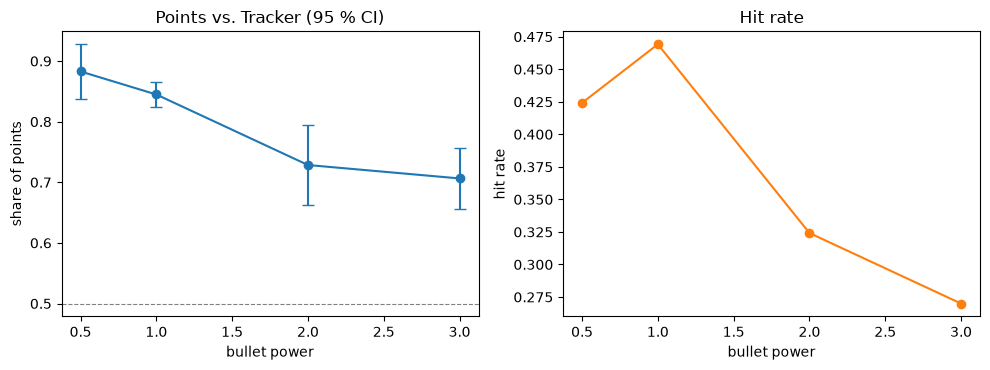

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))
a.errorbar(summary.index, summary["share"], yerr=summary["ci95"], fmt="o-", capsize=4)
a.axhline(0.5, color="grey", lw=0.8, ls="--")
a.set(xlabel="bullet power", ylabel="share of points", title="Points vs. Tracker (95 % CI)")
b.plot(summary.index, summary["hit_rate"], "o-", color="tab:orange")
b.set(xlabel="bullet power", ylabel="hit rate", title="Hit rate")
plt.tight_layout()

## Reading the result

- **Hit rate falls with power** (power 1 against 0.5 is within the noise): strong
  bullets are slower, so the enemy has more time to move away from the predicted
  point.
- **Points fall too: low power wins against Tracker.** A power-3 hit does 16
  damage and a power-0.5 hit only 2, but weak bullets fire far more often (gun
  heat 1.1 instead of 1.6 per shot), cost less energy, and hit more. Against a
  bot that keeps its distance, that adds up.
- **Look at the intervals, not just the means:** 0.5 and 1.0 overlap each other,
  but not 2.0 or 3.0. More seeds make intervals narrower (by √n: four times the
  seeds, half the width), which matters when two options are close.

The answer depends on the opponent: try the same experiment against `SpinBot`
(exercise 1) before you hard-code a power.

## Paired comparison

Because every power met the same seeds, we can compare two powers seed by seed.
That removes the luck both share and is more sensitive. Here it confirms what the
plot shows: power 2 scores less than power 0.5, seed after seed.

In [6]:
wide = df.pivot(index="seed", columns="power", values="share")
diff = wide[2.0] - wide[0.5]
ci = T_95 * diff.std() / np.sqrt(len(diff))
print(f"power 2.0 vs 0.5: {diff.mean():+.3f} share (95 % CI ± {ci:.3f}), "
      f"better in {(diff > 0).sum()} of {len(diff)} seeds")

power 2.0 vs 0.5: -0.154 share (95 % CI ± 0.081), better in 1 of 12 seeds


## Exercises

1. Repeat against `SpinBot` (`from terrabots.agents.spin_bot import SpinBot`).
   Does the best power depend on the opponent?
2. Repeat on `terrain="procedural"`. Does terrain change the answer? (Hills
   block bullets, so fewer, stronger shots might pay off.)
3. Instead of a fixed power, fire `min(3, 12 / distance)`. Test it against the
   best fixed power with a paired comparison.
4. Save results with `res.save("results/")` and load the CSV in another tool.